In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/regression/capm_data(1).csv


# Week 11 – Python Practice: Simple Regression and the CAPM

## Objective
In this notebook you will run a **simple linear regression** in Python. We use the **Capital Asset Pricing Model (CAPM)** to estimate the **beta** of BP, which measures how sensitive BP's return is to the return on the FTSE 100.

By the end you will be able to:
- identify the **dependent variable (y)**, the **independent variable (x)** and the **error term (u)**
- estimate **α (alpha)** and **β (beta)** with OLS
- read the regression output: **coefficients, t-ratios, p-values and R²**
- check the residuals

## About the Data

| Variable | Description | Source |
|---|---|---|
| `FTSE100` | Monthly return on the FTSE 100 index (%) | Yahoo Finance (^FTSE) |
| `BP` | Monthly return on BP plc shares (%) | Yahoo Finance (BP.L) |
| `RF` | Monthly risk-free rate (%): UK 3-month interest rate ÷ 12 | FRED (IR3TIB01GBM156N) |

- **Frequency:** monthly
- **Period:** February 2010 – December 2025 (191 months)
- **Why returns and not prices?** Regression needs stationary data (Week 8). Prices trend upwards over time; returns do not.

### The CAPM model

$$(R_{BP} - r_f)_t = \alpha + \beta\,(R_{M} - r_f)_t + u_t$$

- **y** = BP's excess return: the return above the risk-free rate (what we want to explain)
- **x** = the FTSE 100 excess return: the market (what we use to explain y)
- **β** = BP's sensitivity to the market
- **α** = the return not explained by the market (CAPM predicts α = 0)
- **u** = everything else that moves BP's return (oil prices, company news, ...)

## Step 1: Import the Libraries
- `pandas` handles the data table
- `statsmodels` runs the regression
- `matplotlib` draws the charts

In [2]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

## Step 2: Load the Data
Upload `capm_data.csv` to your notebook (right-hand panel → **Upload**). Then read it in, using the date column as the index.

> In Kaggle, the file path will look like `/kaggle/input/<your-dataset-name>/capm_data.csv`. Copy it from the right-hand panel.

In [3]:
df = pd.read_csv("/kaggle/input/datasets/robinaz/regression/capm_data(1).csv", index_col=0)
df.head()

,FTSE100,BP,RF
2010-02,3.199383,-1.380943,0.052758
2010-03,6.071530,7.724251,0.053791
2010-04,-2.223753,-7.683694,0.054660
2010-05,-6.570866,-14.022620,0.058094
2010-06,-5.232827,-35.549690,0.060699


## Step 3: Explore the Data
Before running a regression, always look at the data:
- How many observations do we have?
- Are there any missing values?
- What are the average return and the volatility (standard deviation) of each series?

In [4]:
print("Number of observations:", len(df))
print("\nMissing values:\n", df.isnull().sum())
df.describe().round(3)

Number of observations: 191

Missing values:
 FTSE100    0
BP         0
RF         0
dtype: int64


,FTSE100,BP,RF
count,191.000,191.000,191.000
mean,0.401,0.137,0.120
std,3.472,7.589,0.139
min,-13.807,-35.550,0.002
25%,-1.710,-4.446,0.043
50%,0.800,-0.043,0.058
75%,2.677,3.944,0.087
max,12.352,27.297,0.461


### Interpretation
- We have **191 monthly observations** (Feb 2010 – Dec 2025) and **no missing values**, so the data is ready to use.
- **Volatility:** BP's standard deviation (**7.59%**) is more than **twice** that of the FTSE 100 (**3.47%**). BP is a much riskier investment than the market as a whole.
- **Average return:** the FTSE 100 earned **0.40%** a month on average, while BP earned only **0.14%**, barely above the risk-free rate (**0.12%**). BP took more risk but did not earn more over this period.
- **Extreme months:** BP's worst month was **−35.55%** (June 2010, after the Deepwater Horizon oil spill) and its best was **+27.30%**. The FTSE 100's range (−13.8% to +12.4%) is much narrower.
- **Risk-free rate:** very low for most of the period (median 0.06% a month), rising to 0.46% a month after interest rates went up in 2022–23.

## Step 4: Create the Excess Returns
CAPM explains the return **above** the risk-free rate, so we subtract `RF` from both the share return and the market return.

In [5]:
df["BP_excess"]   = df["BP"] - df["RF"]
df["FTSE_excess"] = df["FTSE100"] - df["RF"]

df[["BP_excess", "FTSE_excess"]].head()

,BP_excess,FTSE_excess
2010-02,-1.433702,3.146625
2010-03,7.670460,6.017740
2010-04,-7.738354,-2.278413
2010-05,-14.080714,-6.628960
2010-06,-35.610390,-5.293526


## Step 5: Visualise the Relationship
A scatter plot shows whether y and x move together. If the points slope upwards, BP tends to rise when the market rises.

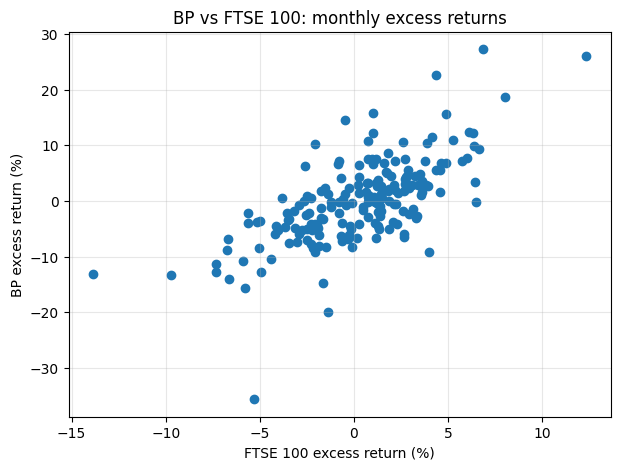

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(df["FTSE_excess"], df["BP_excess"])
plt.xlabel("FTSE 100 excess return (%)")
plt.ylabel("BP excess return (%)")
plt.title("BP vs FTSE 100: monthly excess returns")
plt.grid(alpha=0.3)
plt.show()

### Interpretation
- The points **slope upwards**: when the FTSE 100 has a good month, BP usually does too. This is a **positive relationship** between y and x.
- The points are **widely spread** around the trend, so the market explains part of BP's movement but not all of it.
- One point stands out at about **−35%** on the y-axis: June 2010, the **Deepwater Horizon** oil spill. BP fell sharply while the market fell only about 5%. This was **firm-specific news** that ends up in the **error term**.

## Step 6: Define y and x
- **y** (dependent variable) = `BP_excess`
- **x** (independent variable) = `FTSE_excess`

`sm.add_constant()` adds a column of 1s so that Python also estimates the **intercept α**. Without it, the line is forced through zero.

In [7]:
y = df["BP_excess"]
X = sm.add_constant(df["FTSE_excess"])

X.head()

,const,FTSE_excess
2010-02,1.0,3.146625
2010-03,1.0,6.017740
2010-04,1.0,-2.278413
2010-05,1.0,-6.628960
2010-06,1.0,-5.293526


## Step 7: Run the Regression (OLS)
Ordinary least squares (OLS) chooses α and β to **minimise the sum of squared residuals**, giving the best-fitting line through the points.

In [8]:
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              BP_excess   R-squared:                       0.463
Model:                            OLS   Adj. R-squared:                  0.460
Method:                 Least Squares   F-statistic:                     162.9
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           2.62e-27
Time:                        18:37:57   Log-Likelihood:                -598.31
No. Observations:                 191   AIC:                             1201.
Df Residuals:                     189   BIC:                             1207.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.4019      0.405     -0.992      

## Step 8: Interpret the Results
Look at the middle table: the `const` row is **α** and the `FTSE_excess` row is **β**.

| What to look at | Where in the output | How to interpret it |
|---|---|---|
| **β (beta)** | `coef` on `FTSE_excess` | When the FTSE 100 excess return rises by 1 percentage point, BP's rises by β points on average. **β > 1**: riskier than the market. **β < 1**: less risky. |
| **Is β significant?** | `P>|t|` on `FTSE_excess` | H₀: β = 0. If **p < 0.05** (or \|t\| > 2), reject H₀: the market does explain BP's returns. |
| **α (alpha)** | `coef` and `P>|t|` on `const` | CAPM predicts α = 0. If **p > 0.05**, α is not significantly different from zero, which is consistent with CAPM. |
| **R²** | `R-squared` (top right) | The share of BP's ups and downs explained by the market. For example, 0.30 means 30%. |
| **Durbin–Watson** | bottom of the output | Close to **2** is fine. Well below 2 means positive autocorrelation in the errors. |

In [9]:
alpha, beta = model.params
p_alpha, p_beta = model.pvalues

print(f"Alpha (α): {alpha:.3f}   p-value: {p_alpha:.3f}")
print(f"Beta  (β): {beta:.3f}   p-value: {p_beta:.3f}")
print(f"R-squared: {model.rsquared:.3f}")

Alpha (α): -0.402   p-value: 0.322
Beta  (β): 1.489   p-value: 0.000
R-squared: 0.463


### Interpretation

**1. The fitted model**

$$\widehat{(R_{BP} - r_f)}_t = -0.40 + 1.49\,(R_{M} - r_f)_t$$

**2. Beta (β̂ = 1.49)**
- When the FTSE 100 excess return rises by **1 percentage point**, BP's excess return rises by about **1.49 points** on average.
- **β > 1**, so BP is **riskier than the market**: it amplifies market movements in both directions. If the market falls 10%, we expect BP to fall about 15%.
- **Is β significant?** t = **12.76** and p = **0.000** < 0.05, so we **reject H₀: β = 0**. The market has a strong, significant effect on BP's returns.
- The 95% confidence interval for β is **[1.26, 1.72]**. It does **not include 1**, so BP is **significantly** more risky than the market.

**3. Alpha (α̂ = −0.40)**
- After allowing for market risk, BP earned about **0.40% a month less** than CAPM predicts.
- But t = **−0.99** and p = **0.322** > 0.05, so we **cannot reject H₀: α = 0**. The alpha is **not significantly different from zero**.
- This is **consistent with CAPM**: BP's return is explained by its market risk, with no significant abnormal return.

**4. Goodness of fit (R² = 0.463)**
- The FTSE 100 explains **46.3%** of the ups and downs in BP's excess return.
- The remaining **53.7%** is **firm-specific risk**: oil prices, company news, accidents, strategy changes. This all sits in the error term uₜ.
- That is much higher than Brooks' Ford example (R² = 0.003). BP is a large FTSE 100 company, so it moves closely with its own market.

**5. Durbin–Watson (2.24)**
- Close to **2**, so there is **no serious autocorrelation** in the residuals.

**6. Jarque–Bera (p = 0.000) and kurtosis (6.56)**
- The residuals are **not normally distributed**. They have **fat tails** (kurtosis well above 3) because of a few extreme months, such as June 2010. This is very common with financial returns.
- With 191 observations, the t-tests are still reasonably reliable.

## Step 9: Draw the Fitted Regression Line
The red line is the **fitted line**, $\hat{y} = \hat{\alpha} + \hat{\beta}x$. The vertical gap between each point and the line is a **residual**.

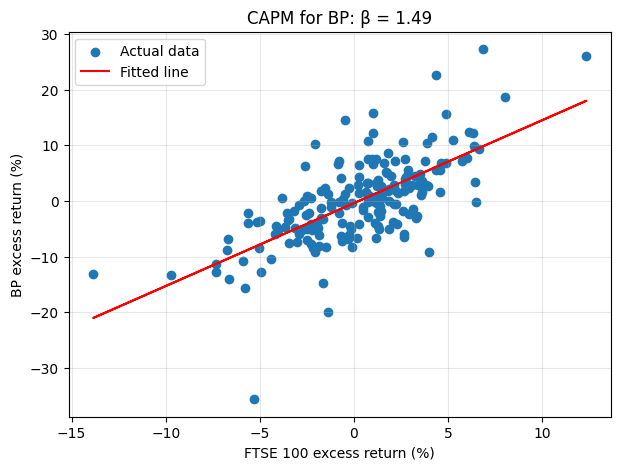

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(df["FTSE_excess"], df["BP_excess"], label="Actual data")
plt.plot(df["FTSE_excess"], model.fittedvalues, color="red", label="Fitted line")
plt.xlabel("FTSE 100 excess return (%)")
plt.ylabel("BP excess return (%)")
plt.title(f"CAPM for BP: β = {beta:.2f}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretation
- The red fitted line slopes **upwards with slope 1.49**, so it is **steeper** than a 45° line. BP moves more than one-for-one with the market.
- **Example forecast:** if the FTSE 100 excess return is **+5%** in a month, the model predicts BP's excess return as −0.40 + 1.49 × 5 = **+7.05%**.
- Many points lie far from the line. Those vertical gaps are the **residuals**, and they explain why R² is 0.46 rather than close to 1.

## Step 10: Check the Residuals
We never see the true errors $u_t$, so we check the residuals $\hat{u}_t$ instead.
- The residuals should move randomly around zero.
- If they are bigger in some periods (e.g. 2020), the errors are **heteroscedastic** (volatility clustering).

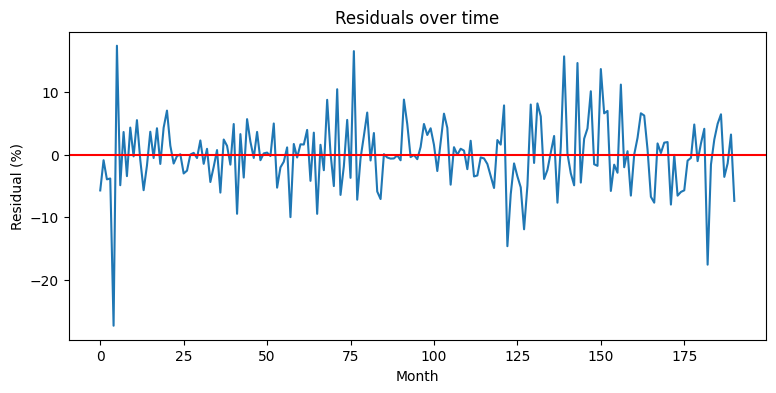

In [11]:
plt.figure(figsize=(9, 4))
plt.plot(model.resid.values)
plt.axhline(0, color="red")
plt.title("Residuals over time")
plt.xlabel("Month")
plt.ylabel("Residual (%)")
plt.show()

### Interpretation
- The residuals move **around zero** with no clear pattern. This is good: the model is not systematically over- or under-predicting.
- The biggest negative residual (about **−27%**, near the start) is **June 2010**, the Deepwater Horizon oil spill.
- The spread is **not the same everywhere**. Residuals are larger around **2015–16** (the oil price slump), **2020** (COVID-19 and the oil price crash) and **2022 onwards** (the energy crisis), and calmer in between.
- This is a sign of **heteroscedasticity** (volatility clustering, Week 8). That is why we also use **robust standard errors**.

### Robust standard errors
If the residuals do not have the same spread over time, we use **robust standard errors**. The coefficients stay the same and only the standard errors and p-values change.

In [12]:
model_robust = sm.OLS(y, X).fit(cov_type="HC1")
print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:              BP_excess   R-squared:                       0.463
Model:                            OLS   Adj. R-squared:                  0.460
Method:                 Least Squares   F-statistic:                     118.0
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           1.15e-21
Time:                        18:37:58   Log-Likelihood:                -598.31
No. Observations:                 191   AIC:                             1201.
Df Residuals:                     189   BIC:                             1207.
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.4019      0.406     -0.990      

### Interpretation
- The **coefficients do not change**: α̂ = −0.40 and β̂ = 1.49 are exactly the same as before.
- The **standard error of β rises** from **0.117 to 0.137**, so the t-ratio falls from **12.76 to 10.86**. The ordinary standard errors were slightly too small, which is what we expect with heteroscedasticity.
- **β is still highly significant** (p = 0.000), and **α is still not significant** (p = 0.322).
- **Conclusion:** our results are **robust**. Heteroscedasticity does not change the conclusions.

## Summary
- Regression explains **y** using **x**: here, BP's excess return using the FTSE 100 excess return.
- **β̂ = 1.49** (significant): BP is about **1.5 times as sensitive** to the market as the average share, so it is a **high-risk stock**.
- **α̂ = −0.40** (not significant): there is no abnormal return, which is **consistent with CAPM**.
- **R² = 0.46**: the market explains almost half of BP's movements, and the rest is firm-specific risk.
- The residuals show **fat tails and volatility clustering**, but **robust standard errors** give the same conclusions.

**Next week:** Time series modelling (AR, MA, ARMA and ARIMA).